## **0. Download dataset**

In [1]:
# https://drive.google.com/file/d/1XAutXqbRQPz1dFmiXjMPo2JM4BpAL2wp/view?usp=sharing
#!gdown 1XAutXqbRQPz1dFmiXjMPo2JM4BpAL2wp -O ../Data
#!unzip -q ../Data/[Data]-img-cls-scenes-classification.zip -d ../Data

## **1. Import libraries**

In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm import tqdm

In [3]:
def set_seed(seed=59):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed = 59
set_seed(seed)
print(f"Using seed {seed}")

Using seed 59


## **2. Dataset structure and locations**

In [4]:
root_dir = Path('../Data/scenes_classification')
train_dir = root_dir / 'train'
val_dir = root_dir / 'val'

classes = {
    label_idx: class_name
    for label_idx, class_name in enumerate(sorted(os.listdir(train_dir)))
}

X_train, y_train = [], []
X_test, y_test = [], []

for dataset_path in [train_dir, val_dir]:
    for label_idx, class_name in classes.items():
        class_dir = dataset_path / class_name
        if not class_dir.exists():
            continue
        for img_filename in sorted(class_dir.iterdir()):
            if not img_filename.is_file():
                continue
            img_path = str(img_filename)
            if 'train' in str(dataset_path):
                X_train.append(img_path)
                y_train.append(label_idx)
            else:
                X_test.append(img_path)
                y_test.append(label_idx)

print('Train images:', len(X_train))
print('Validation/Test candidates (from val folder):', len(X_test))

Train images: 14034
Validation/Test candidates (from val folder): 3000


## **3. Train, val split**

In [5]:
seed = 0
val_size = 0.2
is_shuffle = True
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=val_size,
    random_state=seed,
    shuffle=is_shuffle,
)
print('Split result:', len(X_train), 'train samples and', len(X_val), 'validation samples')

Split result: 11227 train samples and 2807 validation samples


## **4. Create dataloader**

In [6]:
class ScenesDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.transform = transform
        self.img_paths = X
        self.labels = y

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

In [7]:
def transform(img, img_size=(224, 224)):
    img = img.resize(img_size)
    img = np.array(img)[..., :3]
    tensor_img = torch.tensor(img).permute(2, 0, 1).float()
    normalized_img = tensor_img / 255.0
    return normalized_img

In [8]:
train_dataset = ScenesDataset(X_train, y_train, transform=transform)
val_dataset = ScenesDataset(X_val, y_val, transform=transform)
test_dataset = ScenesDataset(X_test, y_test, transform=transform)

train_batch_size = 32
test_batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=train_batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=test_batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=test_batch_size, shuffle=False)

## **5. Create model**

In [9]:
class BottleneckBlock(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv1 = nn.Conv2d(in_channels, 4 * growth_rate, kernel_size=1, bias=False)
        self.bn2 = nn.BatchNorm2d(4 * growth_rate)
        self.conv2 = nn.Conv2d(4 * growth_rate, growth_rate, kernel_size=3, padding=1, bias=False)
        self.relu = nn.ReLU()

    def forward(self, x: torch.Tesnor):
        res = x.clone()
        x = self.bn1(x)
        x = self.relu(x)
        x = self.conv1(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.conv2(x)
        return torch.cat([res, x], 1)


class DenseBlock(nn.Module):
    def __init__(self, num_layers, in_channels, growth_rate):
        super().__init__()
        layers = []
        for i in range(num_layers):
            layers.append(BottleneckBlock(in_channels + i * growth_rate, growth_rate))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class DenseNet(nn.Module):
    def __init__(self, num_blocks, growth_rate, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 2 * growth_rate, kernel_size=7, padding=3, stride=2, bias=False)
        self.bn1 = nn.BatchNorm2d(2 * growth_rate)
        self.pool1 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.dense_blocks = nn.ModuleList()
        in_channels = 2 * growth_rate
        for i, num_layers in enumerate(num_blocks):
            self.dense_blocks.append(DenseBlock(num_layers, in_channels, growth_rate))
            in_channels += num_layers * growth_rate
            if i != len(num_blocks) - 1:
                out_channels = in_channels // 2
                transitions = nn.Sequential(
                    nn.BatchNorm2d(in_channels),
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.AvgPool2d(kernel_size=2, stride=2),
                )
                self.dense_blocks.append(transitions)
                in_channels = out_channels
        self.bn2 = nn.BatchNorm2d(in_channels)
        self.pool2 = nn.AvgPool2d(kernel_size=7)
        self.relu = nn.ReLU()
        self.fc = nn.Linear(in_channels, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.pool1(x)
        for block in self.dense_blocks:
            x = block(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.pool2(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

n_classes = len(classes)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = DenseNet([6, 12, 24, 16], growth_rate=32, num_classes=n_classes).to(device)
print(model)

DenseNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (dense_blocks): ModuleList(
    (0): DenseBlock(
      (block): Sequential(
        (0): BottleneckBlock(
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (relu): ReLU()
        )
        (1): BottleneckBlock(
          (bn1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (conv1): Conv2d(96, 128, ker

In [10]:
from torchsummary import summary
summary(model, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
       BatchNorm2d-5           [-1, 64, 56, 56]             128
              ReLU-6           [-1, 64, 56, 56]               0
            Conv2d-7          [-1, 128, 56, 56]           8,192
       BatchNorm2d-8          [-1, 128, 56, 56]             256
              ReLU-9          [-1, 128, 56, 56]               0
           Conv2d-10           [-1, 32, 56, 56]          36,864
  BottleneckBlock-11           [-1, 96, 56, 56]               0
      BatchNorm2d-12           [-1, 96, 56, 56]             192
             ReLU-13           [-1, 96, 56, 56]               0
           Conv2d-14          [-1, 128,

## **6. Training**

In [11]:
lr = 1e-2
epochs = 25
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            labels = labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
    dataset_size = len(loader.dataset)
    avg_loss = total_loss / dataset_size if dataset_size else 0.0
    accuracy = correct / dataset_size if dataset_size else 0.0
    return avg_loss, accuracy

def fit(model, train_loader, val_loader, criterion, optimizer, device, epochs):
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        batch_train_losses = []
        model.train()
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} - Training")
        for imgs, labels in train_pbar:
            imgs = imgs.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            batch_train_losses.append(loss.item())
            train_pbar.set_postfix({'loss': loss.item()})
        epoch_loss = sum(batch_train_losses) / len(batch_train_losses)
        train_losses.append(epoch_loss)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        val_losses.append(val_loss)
        print(f'Epoch {epoch + 1}/{epochs} - train loss: {epoch_loss:.4f} - val loss: {val_loss:.4f} - val acc: {val_acc:.4f}')
    return train_losses, val_losses

train_losses, val_losses = fit(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs,
)

val_loss, val_acc = evaluate(model, val_loader, criterion, device)
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print('Evaluation on val / test dataset')
print('Val accuracy:', val_acc)
print('Test accuracy:', test_acc)

Epoch 1/25 - Training: 100%|██████████| 351/351 [03:00<00:00,  1.95it/s, loss=0.476]


Epoch 1/25 - train loss: 0.8807 - val loss: 1.2139 - val acc: 0.5871


Epoch 2/25 - Training: 100%|██████████| 351/351 [03:06<00:00,  1.88it/s, loss=0.475]


Epoch 2/25 - train loss: 0.5973 - val loss: 0.7615 - val acc: 0.7492


Epoch 3/25 - Training: 100%|██████████| 351/351 [02:55<00:00,  2.00it/s, loss=0.44] 


Epoch 3/25 - train loss: 0.5011 - val loss: 1.5468 - val acc: 0.5739


... (40 outputs left out)

Epoch 24/25 - Training: 100%|██████████| 351/351 [02:54<00:00,  2.01it/s, loss=0.235]  


Epoch 24/25 - train loss: 0.0927 - val loss: 1.0841 - val acc: 0.7545


Epoch 25/25 - Training: 100%|██████████| 351/351 [02:55<00:00,  2.00it/s, loss=0.0564] 


Epoch 25/25 - train loss: 0.0773 - val loss: 0.4943 - val acc: 0.8625
Evaluation on val / test dataset
Val accuracy: 0.8624866405415034
Test accuracy: 0.865


## Training Loss Visualization

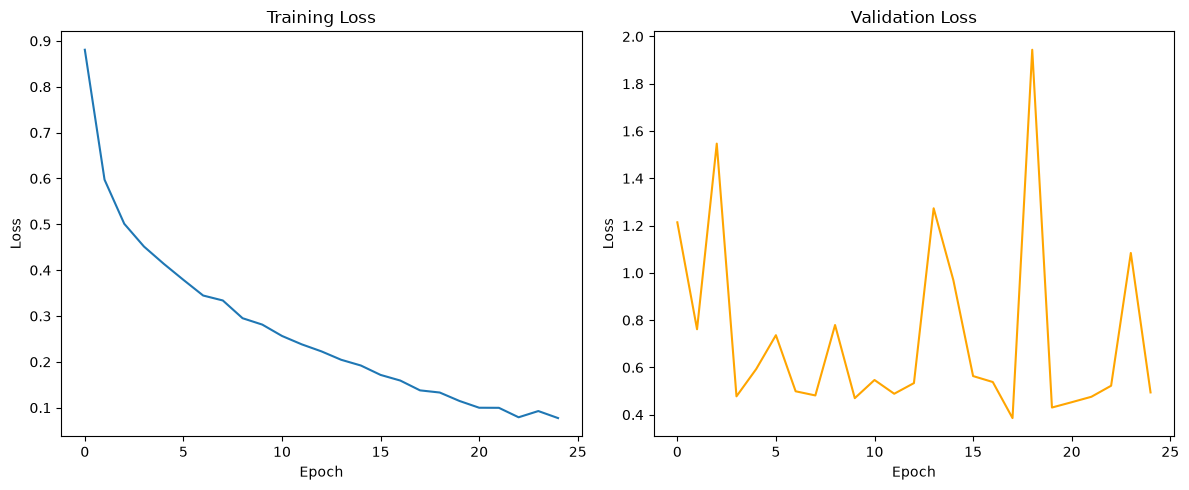

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(train_losses)
ax[0].set_title('Training Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[1].plot(val_losses, color='orange')
ax[1].set_title('Validation Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
plt.tight_layout()
plt.show()

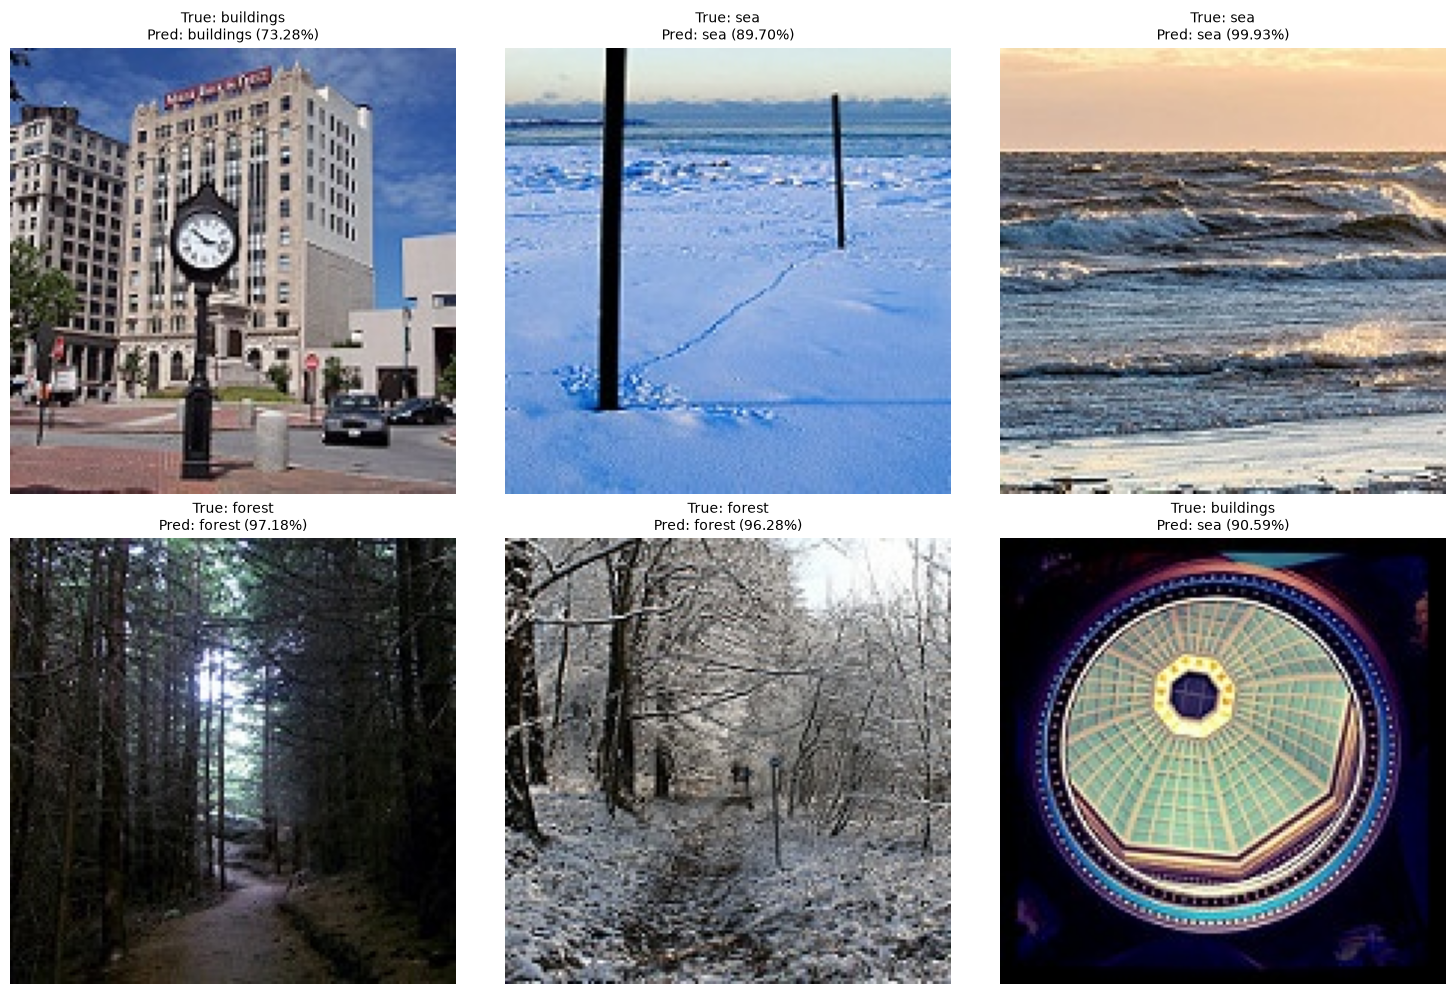

In [13]:
def predict_sample(model, img_path, transform, device, classes):
    model.eval()
    img = Image.open(img_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.softmax(output, dim=1)
        pred_class = output.argmax(dim=1).item()
        pred_prob = probs[0, pred_class].item()
    return classes[pred_class], pred_prob, img, probs[0].cpu().numpy()

# Test inference on random samples from test set
num_samples = 6
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

sample_indices = np.random.choice(len(X_test), num_samples, replace=False)
for idx, sample_idx in enumerate(sample_indices):
    img_path = X_test[sample_idx]
    true_label = classes[y_test[sample_idx]]

    pred_class, pred_prob, img, probs = predict_sample(model, img_path, transform, device, classes)

    axes[idx].imshow(img)
    axes[idx].set_title(f'True: {true_label}\nPred: {pred_class} ({pred_prob:.2%})', fontsize=10)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()